# Modeling Human Activity States with a Hidden Markov Model

**Formative 2 – Machine Learning Techniques II**

This notebook takes smartphone accelerometer and gyroscope recordings (Sensor Logger app),
cleans and harmonizes them, extracts time- and frequency-domain features over sliding windows,
and trains a Gaussian Hidden Markov Model **implemented from scratch with NumPy**
(forward–backward, Viterbi and Baum–Welch). The model is then evaluated on recordings that were
never used for training.

**Hidden states (Z):** Still (phone on a table), Standing, Walking, Jumping

**Pipeline**
1. Load the raw exports and inspect sampling rates
2. Harmonize: align accelerometer + gyroscope on one time grid, anti-alias, resample to a common rate, trim edges
3. Window the signals and extract features
4. Normalize (Z-score fitted on training data only)
5. Define and train the HMM (supervised initialization → Baum–Welch with a log-likelihood convergence check)
6. Decode unseen test sequences with Viterbi and evaluate (sensitivity, specificity, accuracy, confusion matrix)

In [1]:
import os, glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

np.random.seed(42)
pd.set_option('display.precision', 3)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10})

DATA_RAW   = 'data/raw'
DATA_CLEAN = 'data/clean'
DATA_TEST  = 'data/test_sequences'
FIG_DIR    = 'figures'
for d in [DATA_CLEAN, DATA_TEST, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

ACTIVITIES = ['standstill', 'standing', 'walking', 'jumping']        # hidden-state order
LABELS     = {'standstill': 'Still', 'standing': 'Standing', 'walking': 'Walking', 'jumping': 'Jumping'}
COLORS     = {'standstill': '#2a78d6', 'standing': '#eb6834', 'walking': '#1baf7a', 'jumping': '#eda100'}
K = len(ACTIVITIES)

# ---- Harmonization / windowing parameters (justified in the markdown below) ----
TARGET_FS = 50      # Hz – common sampling rate for every phone
TRIM_S    = 0.5     # s  – removed from start and end of each recording (tapping start/stop)
WIN_S     = 2.0     # s  – window length  -> 100 samples at 50 Hz
HOP_S     = 1.0     # s  – hop (50 % overlap) -> 50 samples at 50 Hz
WIN  = int(WIN_S * TARGET_FS)
HOP  = int(HOP_S * TARGET_FS)
TEST_SESSION = 5    # recording session held out as unseen data

def savefig(name):
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=150, bbox_inches='tight')

## 1. Load the raw recordings and inspect sampling rates

Each recording is a Sensor Logger export containing `Accelerometer.csv` (linear acceleration, gravity removed),
`TotalAcceleration.csv` (raw accelerometer including gravity), `Gyroscope.csv` and `Metadata.csv`.
Every file has a nanosecond `time` timestamp column and `seconds_elapsed`.
Recordings are named `<activity>_<NN>` in chronological order; `data/recordings_manifest.csv` maps each one to
its original Sensor Logger name and recording session (5 sessions × 10 recordings per activity).

In [2]:
manifest = pd.read_csv('data/recordings_manifest.csv')
SENSORS = {'Accelerometer': 'lin', 'TotalAcceleration': 'acc', 'Gyroscope': 'gyro'}

def load_raw(rec_dir):
    """Return {prefix: DataFrame(t, x, y, z)} with t in seconds (from the ns timestamp) and the metadata row."""
    out = {}
    for fname, prefix in SENSORS.items():
        df = pd.read_csv(f'{rec_dir}/{fname}.csv')
        df = df.sort_values('time').drop_duplicates('time')
        out[prefix] = pd.DataFrame({'t': df['time'].values / 1e9, 'x': df['x'].values,
                                    'y': df['y'].values, 'z': df['z'].values})
    meta = pd.read_csv(f'{rec_dir}/Metadata.csv').iloc[0]
    return out, meta

rows = []
for _, r in manifest.iterrows():
    sig, meta = load_raw(f"{DATA_RAW}/{r.activity}/{r.recording}")
    row = {'recording': r.recording, 'activity': r.activity, 'session': r.session,
           'device': meta['device name'], 'platform': meta['platform'],
           'requested_interval_ms': str(meta['sampleRateMs']).split('|')[0]}
    for p, df in sig.items():
        dt = np.diff(df.t.values)
        row[f'{p}_fs_hz'] = 1 / np.median(dt)
        row[f'{p}_dt_std_ms'] = dt.std() * 1000
        row[f'{p}_max_gap_ms'] = dt.max() * 1000
    row['duration_s'] = min(df.t.iloc[-1] for df in sig.values()) - max(df.t.iloc[0] for df in sig.values())
    rows.append(row)
raw_info = pd.DataFrame(rows)

print('Devices used:')
print(raw_info.groupby(['device', 'platform', 'requested_interval_ms']).size().rename('recordings').to_string(), '\n')
summary = raw_info.groupby('activity').agg(files=('recording', 'count'),
                                           total_duration_s=('duration_s', 'sum'),
                                           mean_duration_s=('duration_s', 'mean'),
                                           min_duration_s=('duration_s', 'min'),
                                           acc_fs_hz=('acc_fs_hz', 'median'),
                                           gyro_fs_hz=('gyro_fs_hz', 'median'),
                                           worst_gap_ms=('acc_max_gap_ms', 'max')).loc[ACTIVITIES]
summary

Devices used:
device    platform  requested_interval_ms
SM-G973F  android   10                       200 



,files,total_duration_s,mean_duration_s,min_duration_s,acc_fs_hz,gyro_fs_hz,worst_gap_ms
activity,,,,,,,
standstill,50,311.289,6.226,4.650,100.0,100.0,140.831
standing,50,283.182,5.664,4.651,100.0,100.0,150.014
walking,50,283.948,5.679,4.150,100.0,100.0,129.668
jumping,50,298.568,5.971,3.946,100.0,100.0,187.891


**Data volume check.** Every activity has 50 files and well over the required 1 min 30 s of recording.
This is an individual project: all recordings were made by one person with **one phone (Samsung Galaxy S10,
SM-G973F, Android)**. The nominal sampling rate is **100 Hz** (Sensor Logger interval 10 ms) for both the
accelerometer and the gyroscope. Even on one phone, the timestamps are **not perfectly regular**. Most intervals are 10 ms, but there are occasional **dropouts of 100–190 ms** (often right after
recording starts), and the accelerometer and gyroscope are sampled at different instants, so their rows cannot
simply be joined. The plot below shows this.

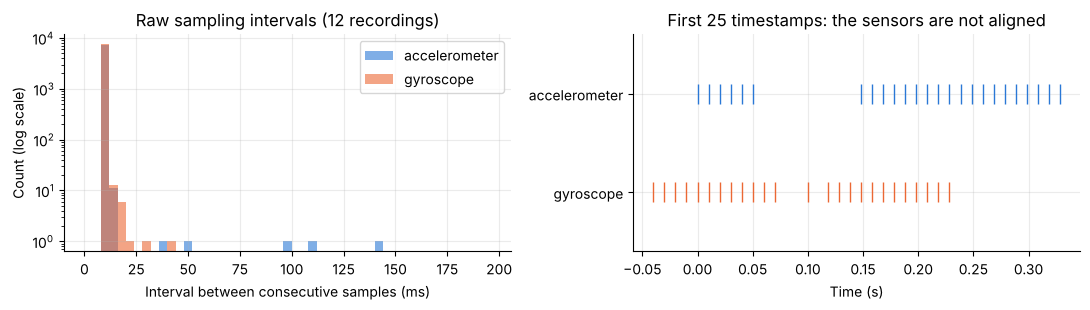

In [3]:
ex = load_raw(f'{DATA_RAW}/walking/walking_01')[0]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for p, c in [('acc', '#2a78d6'), ('gyro', '#eb6834')]:
    dt = np.concatenate([np.diff(load_raw(f'{DATA_RAW}/{a}/{a}_{i:02d}')[0][p].t.values) * 1000
                         for a in ACTIVITIES for i in (1, 25, 50)])
    ax[0].hist(dt, bins=np.arange(0, 200, 4), alpha=.6, color=c, label=p)
ax[0].set(xlabel='Interval between consecutive samples (ms)', ylabel='Count (log scale)', yscale='log',
          title='Raw sampling intervals (12 recordings)')
ax[0].legend(['accelerometer', 'gyroscope'])
ax[1].plot((ex['acc'].t - ex['acc'].t.iloc[0])[:25], np.zeros(25) + 1, '|', ms=14, color='#2a78d6')
ax[1].plot((ex['gyro'].t - ex['acc'].t.iloc[0])[:25], np.zeros(25), '|', ms=14, color='#eb6834')
ax[1].set(yticks=[0, 1], yticklabels=['gyroscope', 'accelerometer'], xlabel='Time (s)',
          title='First 25 timestamps: the sensors are not aligned', ylim=(-.6, 1.6))
plt.tight_layout(); savefig('01_sampling_intervals'); plt.show()

## 2. Harmonization and cleaning

**How sampling rates are handled.** Only one phone was used here, but its two sensors are sampled at different
instants, with dropouts, so they still need harmonizing onto one clean time grid. The same pipeline would also
handle data from other phones, which log at different rates (many Android phones default to ~50 Hz, while iPhones
and this Samsung log at 100 Hz). Every recording goes through the same steps, whatever its original rate:

1. **Common time span.** Keep only the interval where *both* accelerometer and gyroscope have data.
2. **Trim 0.5 s from each end**, which removes the movement of tapping start/stop in the app.
3. **Anti-alias filter.** Linearly interpolate onto a uniform grid at the recording’s own median rate, then apply
   a zero-phase 4th-order Butterworth low-pass at 20 Hz (0.8 × the new Nyquist frequency of 25 Hz). This step is
   skipped automatically if a phone already records at ≤ 50 Hz.
4. **Resample to 50 Hz** by linear interpolation onto a single grid shared by all sensors (one timestamp column).

**Why 50 Hz?** It is a rate every common phone can deliver, so the model would accept recordings from a
different phone without retraining the feature pipeline. Downsampling from 100 Hz also halves the computation. Human movement is concentrated below 20 Hz (walking cadence is ~2 Hz, jumping ~2–3 Hz, and harmonics
stay below ~15 Hz; see the spectrum in Section 3), so a 25 Hz Nyquist frequency loses nothing useful. It is also the rate used by the
UCI-HAR benchmark dataset. The cleaned, labelled recordings are written to `data/clean/<activity>/<recording>.csv`.

In [4]:
def harmonize(sig, target_fs=TARGET_FS, trim_s=TRIM_S):
    """Align all sensors on one uniform time grid at target_fs (anti-aliased, edges trimmed)."""
    t0 = max(df.t.iloc[0] for df in sig.values()) + trim_s
    t1 = min(df.t.iloc[-1] for df in sig.values()) - trim_s
    grid = np.arange(t0, t1, 1 / target_fs)
    out = {'timestamp': grid}
    for p, df in sig.items():
        fs_native = 1 / np.median(np.diff(df.t.values))
        if fs_native > target_fs * 1.05:                    # anti-alias before downsampling
            ugrid = np.arange(df.t.iloc[0], df.t.iloc[-1], 1 / fs_native)
            b, a = butter(4, 0.4 * target_fs / (fs_native / 2), btype='low')
            for ax_ in 'xyz':
                u = filtfilt(b, a, np.interp(ugrid, df.t.values, df[ax_].values))
                out[f'{p}_{ax_}'] = np.interp(grid, ugrid, u)
        else:
            for ax_ in 'xyz':
                out[f'{p}_{ax_}'] = np.interp(grid, df.t.values, df[ax_].values)
    clean = pd.DataFrame(out)
    clean.insert(1, 'seconds', clean.timestamp - clean.timestamp.iloc[0])
    return clean

clean_data = {}
for _, r in manifest.iterrows():
    sig, _ = load_raw(f"{DATA_RAW}/{r.activity}/{r.recording}")
    c = harmonize(sig)
    c['activity'] = r.activity
    os.makedirs(f'{DATA_CLEAN}/{r.activity}', exist_ok=True)
    c.to_csv(f'{DATA_CLEAN}/{r.activity}/{r.recording}.csv', index=False, float_format='%.6f')
    clean_data[r.recording] = c

lens = pd.Series({k: len(v) / TARGET_FS for k, v in clean_data.items()})
print(f'{len(clean_data)} cleaned recordings written to {DATA_CLEAN}/  '
      f'(after trimming: mean {lens.mean():.2f} s, min {lens.min():.2f} s)')
clean_data['walking_01'].head()

200 cleaned recordings written to data/clean/  (after trimming: mean 4.89 s, min 2.96 s)


,timestamp,seconds,lin_x,lin_y,lin_z,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z,activity
0,1.793e+09,0.00,-0.695,0.867,-0.175,-0.121,3.290,9.542,0.046,-0.140,-0.126,walking
1,1.793e+09,0.02,-0.854,0.644,0.173,-0.045,3.431,9.550,0.083,-0.162,-0.079,walking
2,1.793e+09,0.04,-0.883,0.625,0.196,-0.037,3.499,9.875,0.076,-0.254,-0.043,walking
3,1.793e+09,0.06,-0.916,0.618,0.194,0.126,3.503,10.316,0.101,-0.301,0.007,walking
4,1.793e+09,0.08,-1.024,0.591,0.146,0.437,3.490,10.551,0.169,-0.227,0.019,walking


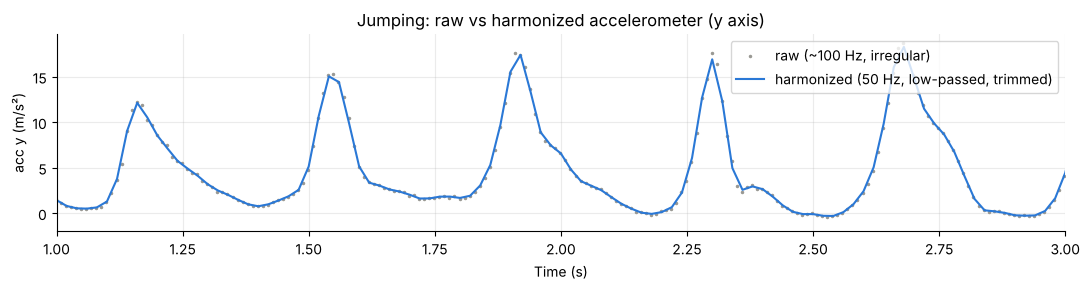

In [5]:
# Before / after harmonization for one recording
raw_ex, _ = load_raw(f'{DATA_RAW}/jumping/jumping_05')
cl_ex = clean_data['jumping_05']
t_ref = raw_ex['acc'].t.iloc[0]
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(raw_ex['acc'].t - t_ref, raw_ex['acc'].y, '.', ms=3, color='#9a9994', label='raw (~100 Hz, irregular)')
ax.plot(cl_ex.timestamp - t_ref, cl_ex.acc_y, '-', lw=1.5, color='#2a78d6', label='harmonized (50 Hz, low-passed, trimmed)')
ax.set(xlim=(1, 3), xlabel='Time (s)', ylabel='acc y (m/s²)', title='Jumping: raw vs harmonized accelerometer (y axis)')
ax.legend(loc='upper right'); plt.tight_layout(); savefig('02_harmonization'); plt.show()

### Visualizing sample data
One cleaned recording per activity: linear acceleration (gravity removed) and angular velocity.
Note the very different y-axis scales. Still and Standing are both near zero, but Standing shows small hand
tremor in the gyroscope. Walking and Jumping are periodic, and Jumping has impacts an order of magnitude larger.

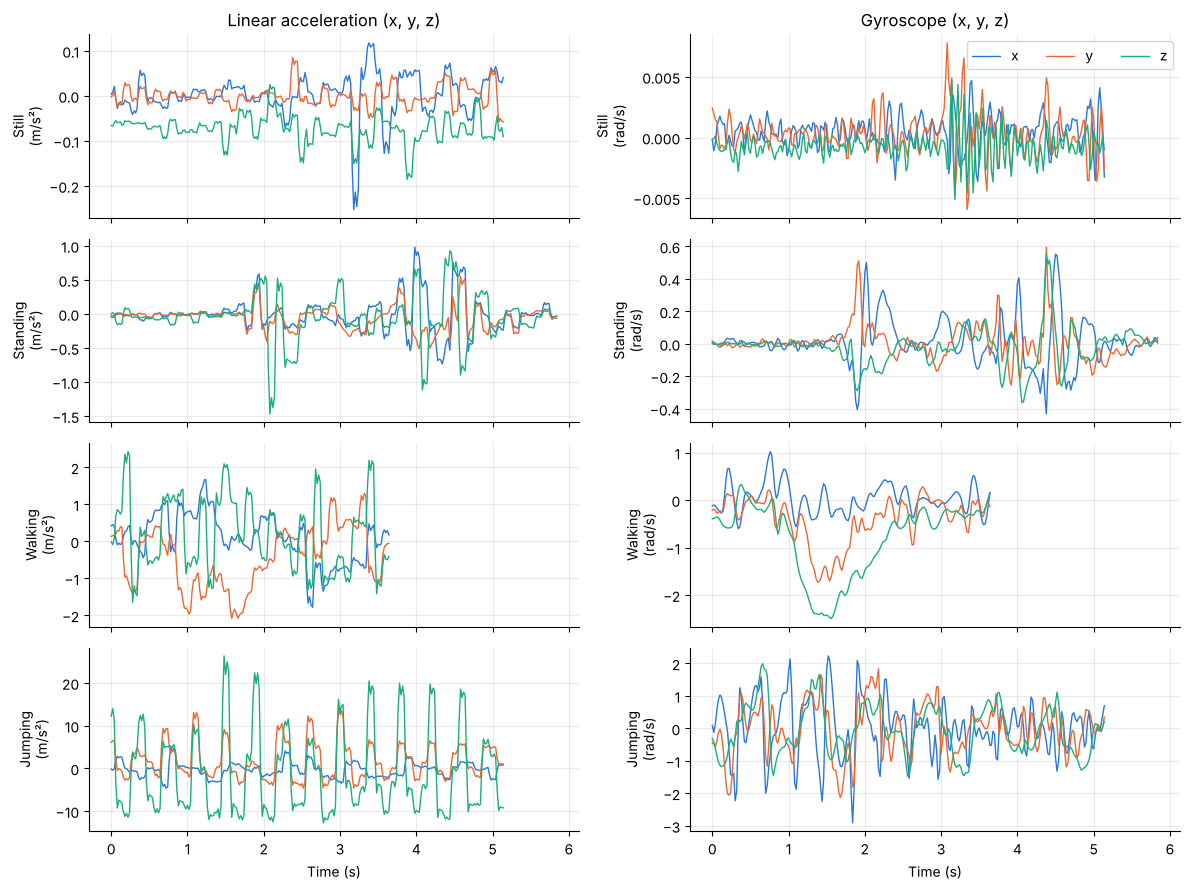

In [6]:
fig, axes = plt.subplots(4, 2, figsize=(12, 9), sharex=True)
for i, a in enumerate(ACTIVITIES):
    c = clean_data[f'{a}_05']
    for j, (p, unit) in enumerate([('lin', 'm/s²'), ('gyro', 'rad/s')]):
        for ax_, col in zip('xyz', ['#2a78d6', '#eb6834', '#1baf7a']):
            axes[i, j].plot(c.seconds, c[f'{p}_{ax_}'], lw=1, color=col, label=ax_)
        axes[i, j].set_ylabel(f'{LABELS[a]}\n({unit})')
axes[0, 0].set_title('Linear acceleration (x, y, z)'); axes[0, 1].set_title('Gyroscope (x, y, z)')
axes[0, 1].legend(ncol=3, loc='upper right'); axes[-1, 0].set_xlabel('Time (s)'); axes[-1, 1].set_xlabel('Time (s)')
plt.tight_layout(); savefig('03_sample_signals'); plt.show()

## 3. Windowing and feature extraction

**Window size and the sampling rate.** At 50 Hz a **2 s window = 100 samples** with a **1 s hop (50 % overlap)**.
* Walking and jumping repeat at ~2–2.5 Hz (see the spectrum below), so 2 s contains about 4–5 full cycles:
  enough for stable variance and FFT estimates. A 1 s window would hold only 2 cycles.
* The FFT frequency resolution is fs/N = 50/100 = **0.5 Hz**, enough to place the jump rhythm (2.5 Hz) and its
  harmonics (5, 7.5 Hz) in separate bins.
* The windows stay short compared with the ~5 s recordings, so each recording gives about 4 overlapping
  observations and the HMM sees a *sequence* (self-transitions) inside every activity bout.
  Longer windows (e.g. 4 s) would leave only 1–2 observations per recording.

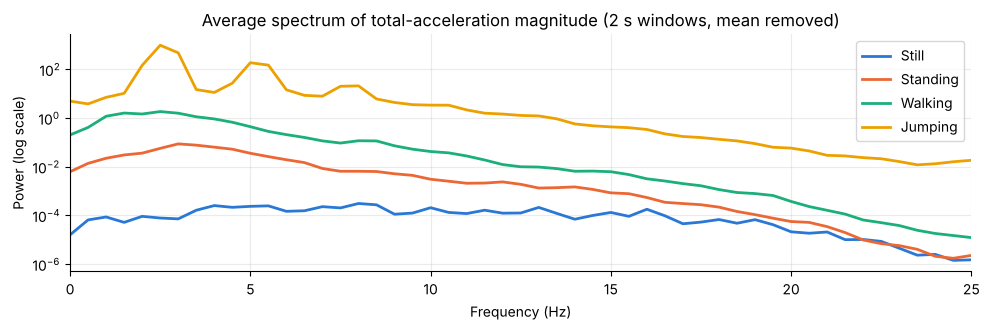

In [7]:
def spectrum(x, fs=TARGET_FS):
    """One-sided power spectrum of a window (mean removed, Hann taper)."""
    x = (x - x.mean()) * np.hanning(len(x))
    P = np.abs(np.fft.rfft(x)) ** 2 / len(x)
    f = np.fft.rfftfreq(len(x), 1 / fs)
    return f, P

# average spectrum of the linear-acceleration magnitude per activity
fig, ax = plt.subplots(figsize=(10, 3.4))
for a in ACTIVITIES:
    Ps = []
    for rec, c in clean_data.items():
        if c.activity.iloc[0] != a: continue
        m = np.sqrt(c.acc_x**2 + c.acc_y**2 + c.acc_z**2).values
        for s in range(0, len(m) - WIN + 1, HOP):
            f, P = spectrum(m[s:s + WIN]); Ps.append(P)
    ax.semilogy(f, np.mean(Ps, axis=0), color=COLORS[a], lw=2, label=LABELS[a])
ax.set(xlabel='Frequency (Hz)', ylabel='Power (log scale)', xlim=(0, 25),
       title='Average spectrum of total-acceleration magnitude (2 s windows, mean removed)')
ax.legend(); plt.tight_layout(); savefig('04_spectrum'); plt.show()

### Features (computed for every 2 s window)

| # | Feature | Domain | Why it separates the activities |
|---|---|---|---|
| 1 | `acc_std`: std of linear-acceleration magnitude | time | Overall movement intensity: Still < Standing ≪ Walking ≪ Jumping |
| 2 | `acc_sma`: signal magnitude area, mean(\|x\|+\|y\|+\|z\|) | time | Energy spent by the body on all three axes; robust to phone orientation |
| 3 | `acc_range`: max − min of total-acceleration magnitude | time | Captures **impacts**: landing from a jump gives peaks of 2–4 g; walking steps are much smaller |
| 4 | `gyro_rms`: RMS of angular-velocity magnitude | time | Rotation: a phone on a table does not rotate at all, a hand-held phone while standing shows small tremor. This is the **key feature for Still vs Standing** |
| 5 | `corr_acc_yz`: correlation between linear-acc y and z axes | time | Jumping is a vertical, single-direction motion (strongly coupled axes); walking mixes forward and vertical motion; still/standing is uncorrelated noise |
| 6 | `dom_freq`: dominant FFT frequency of total-acc magnitude (0.5–20 Hz) | frequency | Rhythm of the movement: jumping locks onto ~2.5 Hz and walking steps fall at ~1.5–3 Hz. Still/Standing have no rhythm, so their peak lands at random higher frequencies (sensor noise) |
| 7 | `spec_energy`: spectral energy of linear-acc magnitude (FFT) | frequency | Total power of the motion; separates the static and dynamic groups by orders of magnitude |
| 8 | `spec_entropy`: normalized spectral entropy of total-acc magnitude (FFT) | frequency | Periodic movement concentrates power in a few bins (low entropy); sensor noise of Still/Standing is spread across all bins (high entropy) |

The frequency features use the **total**-acceleration magnitude (gravity included, mean removed) rather than the
linear one. The magnitude of a signal without gravity is “rectified”, which doubles its apparent frequency (a 2.5 Hz jump
shows up at 5 Hz). With gravity included, the vertical oscillation keeps its true rhythm.
| 9 | `gyro_dom_power`: fraction of gyroscope power in the dominant FFT bin | frequency | Periodicity of rotation: the swing of walking is rhythmic, hand tremor is not |

Intensity features (1, 2, 3, 4, 7) span **several orders of magnitude** (Still ≈ 0.01 m/s², Jumping ≈ 10 m/s²),
so they are log-transformed (`log10`) before normalization; otherwise one Gaussian per state fits them badly.

In [8]:
FEATURES = ['acc_std', 'acc_sma', 'acc_range', 'gyro_rms', 'corr_acc_yz',
            'dom_freq', 'spec_energy', 'spec_entropy', 'gyro_dom_power']
LOG_FEATURES = ['acc_std', 'acc_sma', 'acc_range', 'gyro_rms', 'spec_energy']

def window_features(w):
    """Feature vector for one window (DataFrame slice of a cleaned recording)."""
    lin = w[['lin_x', 'lin_y', 'lin_z']].values
    acc = w[['acc_x', 'acc_y', 'acc_z']].values
    gyr = w[['gyro_x', 'gyro_y', 'gyro_z']].values
    lin_mag, acc_mag, gyr_mag = (np.linalg.norm(v, axis=1) for v in (lin, acc, gyr))

    f, P = spectrum(lin_mag)                       # energy of the body motion (gravity removed)
    fa, Pa = spectrum(acc_mag)                     # rhythm: total acc keeps the true step/jump frequency
    band = (fa >= 0.5) & (fa <= 20)
    Pb = Pa[band]; pn = Pb / (Pb.sum() + 1e-12)
    fg, Pg = spectrum(gyr_mag); Pgb = Pg[(fg >= 0.5) & (fg <= 20)]

    yz = np.corrcoef(lin[:, 1], lin[:, 2])[0, 1]
    return {
        'acc_std':        lin_mag.std(),
        'acc_sma':        np.abs(lin).sum(axis=1).mean(),
        'acc_range':      acc_mag.max() - acc_mag.min(),
        'gyro_rms':       np.sqrt(np.mean(gyr_mag ** 2)),
        'corr_acc_yz':    0.0 if np.isnan(yz) else yz,
        'dom_freq':       fa[band][np.argmax(Pb)],
        'spec_energy':    P.sum(),
        'spec_entropy':   -(pn * np.log2(pn + 1e-12)).sum() / np.log2(len(pn)),
        'gyro_dom_power': Pgb.max() / (Pgb.sum() + 1e-12),
    }

def extract(clean_df):
    feats = [window_features(clean_df.iloc[s:s + WIN]) for s in range(0, len(clean_df) - WIN + 1, HOP)]
    return pd.DataFrame(feats)

win_rows = []
for _, r in manifest.iterrows():
    F = extract(clean_data[r.recording])
    F.insert(0, 'window', range(len(F)))
    F.insert(0, 'session', r.session); F.insert(0, 'activity', r.activity); F.insert(0, 'recording', r.recording)
    win_rows.append(F)
windows = pd.concat(win_rows, ignore_index=True)
for col in LOG_FEATURES:
    windows[col] = np.log10(windows[col] + 1e-6)

print(f'{len(windows)} windows extracted; windows per recording: '
      f'{windows.groupby("recording").size().min()}–{windows.groupby("recording").size().max()}')
windows.groupby('activity')[FEATURES].mean().loc[ACTIVITIES]

664 windows extracted; windows per recording: 1–7


,acc_std,acc_sma,acc_range,gyro_rms,corr_acc_yz,dom_freq,spec_energy,spec_entropy,gyro_dom_power
activity,,,,,,,,,
standstill,-1.980,-1.053,-1.444,-2.985,0.127,8.209,-2.731,0.864,0.141
standing,-1.088,-0.684,-0.244,-1.343,-0.121,4.523,-0.966,0.703,0.235
walking,-0.238,0.302,0.544,-0.041,-0.099,2.382,0.753,0.628,0.498
jumping,0.753,1.184,1.583,0.172,0.786,2.497,2.744,0.445,0.201


## 4. Train / unseen-test split and normalization

The data were recorded in **5 separate sessions** per activity (10 recordings each, several minutes apart, on
24 October 2026). **Session 5 (recordings 41–50 of every activity), the last session recorded, is held out completely.** It is never used for normalization
statistics, initialization or Baum–Welch, so it is genuinely unseen data from a new session.

**Normalization: Z-score** `z = (x − μ_train) / σ_train`, fitted on training windows only.
* The features have very different units (m/s², rad/s, Hz, correlation, entropy). The HMM uses **Gaussian**
  emissions, and Z-scoring puts every dimension on a comparable scale. This keeps covariance matrices
  well-conditioned and stops one large-unit feature from dominating the likelihood.
* Z-score (rather than min–max) is not distorted by a single extreme jump impact, and it suits
  Gaussian modeling because it only shifts and scales each dimension, leaving the shape of the distribution unchanged.
* Fitting μ and σ only on training data avoids leaking information from the test session.

Training windows: 527  | unseen test windows: 137
Training recordings: 160  | unseen test recordings: 40


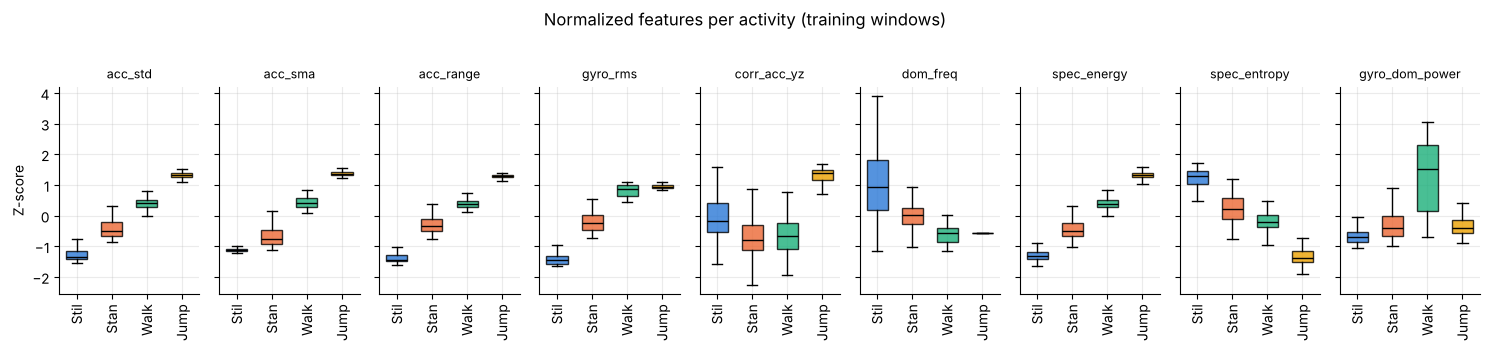

In [9]:
train_mask = windows.session != TEST_SESSION
mu = windows.loc[train_mask, FEATURES].mean()
sd = windows.loc[train_mask, FEATURES].std()
Z = windows.copy()
Z[FEATURES] = (windows[FEATURES] - mu) / sd
print('Training windows:', train_mask.sum(), ' | unseen test windows:', (~train_mask).sum())
print('Training recordings:', windows[train_mask].recording.nunique(),
      ' | unseen test recordings:', windows[~train_mask].recording.nunique())

fig, axes = plt.subplots(1, len(FEATURES), figsize=(15, 3.4), sharey=True)
for ax, ft in zip(axes, FEATURES):
    data = [Z.loc[train_mask & (Z.activity == a), ft].values for a in ACTIVITIES]
    bp = ax.boxplot(data, patch_artist=True, widths=.6, showfliers=False)
    for patch, a in zip(bp['boxes'], ACTIVITIES):
        patch.set_facecolor(COLORS[a]); patch.set_alpha(.8)
    for med in bp['medians']: med.set_color('black')
    ax.set_title(ft, fontsize=9); ax.set_xticks(range(1, K + 1)); ax.set_xticklabels([LABELS[a][:4] for a in ACTIVITIES], rotation=90)
axes[0].set_ylabel('Z-score')
plt.suptitle('Normalized features per activity (training windows)', y=1.02)
plt.tight_layout(); savefig('05_feature_boxplots'); plt.show()

### Building observation sequences

Each recording contains a single activity. To give the HMM realistic **sequences with transitions**,
recordings from the same session are chained into a continuous “routine”. The order of activities follows
plausible human behaviour. A phone lying on a table (Still) must be picked up (Standing) before anyone walks
or jumps with it, so **Still ↔ Walking and Still ↔ Jumping are impossible**. Jumping usually happens during or
after walking. Two consecutive recordings of the same activity simply form a longer bout.
The routine is a Markov chain over *recordings*, weighted by how many recordings of each activity are left:

| from \ to | Still | Standing | Walking | Jumping |
|---|---|---|---|---|
| Still | 0.2 | 0.8 | 0 | 0 |
| Standing | 0.35 | 0.1 | 0.45 | 0.1 |
| Walking | 0 | 0.4 | 0.2 | 0.4 |
| Jumping | 0 | 0.3 | 0.55 | 0.15 |

A small backtracking search makes sure every recording is used exactly once without breaking these rules.
* **Training:** sessions 1–4, each split into 2 routines → 8 training sequences (20 recordings each).
* **Unseen test:** session 5 → **2 test sequences** of 20 recordings each (5 per activity). These are saved
  as `data/test_sequences/test_sequence_{1,2}.csv`.

In [10]:
ROUTINE = {'standstill': {'standstill': .2, 'standing': .8},
           'standing':   {'standstill': .35, 'standing': .1, 'walking': .45, 'jumping': .1},
           'walking':    {'standing': .4, 'walking': .2, 'jumping': .4},
           'jumping':    {'standing': .3, 'walking': .55, 'jumping': .15}}

def build_sequence(recordings, rng):
    """Order single-activity recordings into a realistic routine (each recording used once)."""
    pool = {a: [r for r in recordings if r.startswith(a + '_')] for a in ACTIVITIES}
    for a in pool: rng.shuffle(pool[a])
    left = {a: len(v) for a, v in pool.items()}

    def dfs(cur, acts):
        if not any(left.values()):
            return acts
        opts = ([(a, p * left[a]) for a, p in ROUTINE[cur].items() if left[a]] if cur
                else [(a, left[a]) for a in ACTIVITIES if left[a]])
        while opts:                                   # sample a next activity; backtrack if it leads to a dead end
            w = np.array([p for _, p in opts]); a = opts.pop(rng.choice(len(opts), p=w / w.sum()))[0]
            left[a] -= 1
            res = dfs(a, acts + [a])
            if res: return res
            left[a] += 1
        return None

    acts = dfs(None, [])
    return [pool[a].pop() for a in acts]

def split_halves(recs):
    """Split a session's recordings into two groups with 5 recordings of each activity."""
    g = {a: sorted(r for r in recs if r.startswith(a + '_')) for a in ACTIVITIES}
    return [sum((g[a][:5] for a in ACTIVITIES), []), sum((g[a][5:] for a in ACTIVITIES), [])]

def sequence_arrays(order, Zdf):
    """Stack the normalized window features and integer labels of an ordered recording list."""
    df = pd.concat([Zdf[Zdf.recording == r] for r in order], ignore_index=True)
    return df[FEATURES].values, df.activity.map(ACTIVITIES.index).values, df

def make_sequences(sessions, Zdf, rng):
    seqs = []
    for s in sessions:
        for half in split_halves(list(manifest[manifest.session == s].recording)):
            order = build_sequence(half, rng)
            seqs.append(sequence_arrays(order, Zdf) + (order,))
    return seqs

rng = np.random.default_rng(7)
train_seqs = [s[:3] for s in make_sequences([s for s in range(1, 6) if s != TEST_SESSION], Z, rng)]
test_seqs = []
for i, (X, y, df, order) in enumerate(make_sequences([TEST_SESSION], Z, rng), 1):
    test_seqs.append((X, y, df))
    # save the unseen test sequence as a raw-signal CSV (cleaned 50 Hz samples, in routine order)
    sig = pd.concat([clean_data[r].assign(recording=r) for r in order], ignore_index=True)
    sig.insert(1, 'sequence_time_s', np.arange(len(sig)) / TARGET_FS)
    sig.to_csv(f'{DATA_TEST}/test_sequence_{i}.csv', index=False, float_format='%.6f')
    print(f'Test sequence {i}: {len(order)} recordings, {len(y)} windows, {len(sig)/TARGET_FS:.0f} s of signal')
    print('   order:', ' → '.join(LABELS[r.rsplit("_", 1)[0]] for r in order))
print('Training sequences:', [len(y) for _, y, _ in train_seqs], 'windows')

Test sequence 1: 20 recordings, 68 windows, 101 s of signal
   order: Walking → Jumping → Standing → Walking → Standing → Jumping → Walking → Standing → Walking → Jumping → Walking → Standing → Still → Still → Still → Still → Still → Standing → Jumping → Jumping
Test sequence 2: 20 recordings, 69 windows, 98 s of signal
   order: Jumping → Walking → Standing → Walking → Standing → Walking → Jumping → Walking → Jumping → Standing → Still → Standing → Still → Still → Still → Still → Standing → Jumping → Jumping → Walking
Training sequences: [78, 72, 63, 53, 66, 71, 62, 62] windows


## 5. HMM components and implementation (NumPy, from scratch)

| Element | In this model |
|---|---|
| Hidden states **Z** | 4 activities: Still, Standing, Walking, Jumping |
| Observations **X** | 9-dimensional Z-scored feature vector per 2 s window |
| Transitions **A** (4×4) | P(activity at window t+1 given activity at window t) |
| Emissions **B** | One multivariate Gaussian per state, N(x; μₖ, Σₖ), with full covariance (regularized with 10⁻³·I) |
| Initial **π** | P(first window’s activity), with add-one smoothing because there are only 8 training sequence starts (without it, an activity never seen first gets π = 0 and can never be decoded at t = 0) |

**Algorithms and why they fit the evaluation metrics**
* **Forward–backward** (log-space) computes P(X | λ) and the state posteriors γ and ξ needed for training.
* **Baum–Welch (EM)** re-estimates π, A, μ, Σ to maximize the likelihood of the training sequences. It is
  initialized from labelled windows (supervised counts and per-class Gaussians) so that state *k* keeps the
  meaning of activity *k*. It stops when the improvement in total log-likelihood between iterations is **< ε = 10⁻³**, with a 500-iteration
  safety cap that is only a guard against bugs.
* **Viterbi** returns the single most probable *sequence* of activities. Sensitivity, specificity and accuracy
  are computed per window against the true labels, so we need one hard label per window, and Viterbi gives
  the jointly best path. It uses A to suppress isolated one-window misclassifications (and forbids impossible
  jumps such as Still → Jumping), which raises sensitivity for the confusable Standing/Walking pair.

In [11]:
def safe_log(p):
    """log that maps exact zeros to a very large negative number instead of -inf warnings."""
    return np.log(np.clip(p, 1e-300, None))


def logsumexp(a, axis=None, keepdims=False):
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0)
    out = np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True)) + m
    return out if keepdims else np.squeeze(out, axis=axis)


class GaussianHMM:
    """Hidden Markov Model with full-covariance Gaussian emissions, implemented with NumPy.

    Parameters
    ----------
    n_states : number of hidden states K
    reg      : value added to the covariance diagonal for numerical stability
    """

    def __init__(self, n_states, reg=1e-3):
        self.K, self.reg = n_states, reg
        self.history = []

    # ---------- emissions ----------
    def log_emission(self, X):
        """log N(x_t | mu_k, Sigma_k) for every t, k  -> (T, K)."""
        T, D = X.shape
        out = np.empty((T, self.K))
        for k in range(self.K):
            L = np.linalg.cholesky(self.covs[k])
            diff = np.linalg.solve(L, (X - self.means[k]).T)          # (D, T)
            maha = np.sum(diff ** 2, axis=0)
            logdet = 2 * np.sum(np.log(np.diag(L)))
            out[:, k] = -0.5 * (D * np.log(2 * np.pi) + logdet + maha)
        return out

    # ---------- supervised initialization ----------
    def init_from_labels(self, seqs):
        """Estimate pi, A, mu, Sigma by counting on labelled sequences [(X, y), ...]."""
        D = seqs[0][0].shape[1]
        pi = np.ones(self.K); A = np.ones((self.K, self.K))         # +1 Laplace smoothing
        for X, y in seqs:
            pi[y[0]] += 1
            for a, b in zip(y[:-1], y[1:]): A[a, b] += 1
        self.pi = pi / pi.sum(); self.A = A / A.sum(1, keepdims=True)
        Xall = np.vstack([X for X, _ in seqs]); yall = np.concatenate([y for _, y in seqs])
        self.means = np.array([Xall[yall == k].mean(0) for k in range(self.K)])
        self.covs = np.array([np.cov(Xall[yall == k].T) + self.reg * np.eye(D) for k in range(self.K)])
        return self

    # ---------- forward-backward ----------
    def forward_backward(self, X):
        logB = self.log_emission(X)
        T = len(X); logA = safe_log(self.A)
        la = np.empty((T, self.K)); lb = np.zeros((T, self.K))
        la[0] = safe_log(self.pi) + logB[0]
        for t in range(1, T):
            la[t] = logB[t] + logsumexp(la[t - 1][:, None] + logA, axis=0)
        for t in range(T - 2, -1, -1):
            lb[t] = logsumexp(logA + logB[t + 1] + lb[t + 1], axis=1)
        loglik = logsumexp(la[-1])
        gamma = np.exp(la + lb - loglik)                              # P(z_t = k | X)
        xi = np.exp(la[:-1, :, None] + logA[None] + (logB[1:] + lb[1:])[:, None, :] - loglik)
        return loglik, gamma, xi

    def score(self, X):
        return self.forward_backward(X)[0]

    # ---------- Viterbi ----------
    def viterbi(self, X):
        """Most likely state path and its log-probability."""
        logB = self.log_emission(X); logA = safe_log(self.A)
        T = len(X)
        delta = np.empty((T, self.K)); psi = np.zeros((T, self.K), dtype=int)
        delta[0] = safe_log(self.pi) + logB[0]
        for t in range(1, T):
            cand = delta[t - 1][:, None] + logA                      # (from, to)
            psi[t] = np.argmax(cand, axis=0)
            delta[t] = cand[psi[t], range(self.K)] + logB[t]
        path = np.empty(T, dtype=int); path[-1] = np.argmax(delta[-1])
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path, delta[-1].max()

    # ---------- Baum-Welch ----------
    def baum_welch(self, seqs, tol=1e-3, max_iter=500, verbose=True):
        """EM on unlabelled sequences [X, ...]; stops when the total log-likelihood
        improves by less than tol (epsilon) between two iterations."""
        D = seqs[0].shape[1]
        prev = -np.inf
        for it in range(1, max_iter + 1):
            pi_acc = np.zeros(self.K); A_num = np.zeros((self.K, self.K))
            g_sum = np.zeros(self.K); mean_num = np.zeros((self.K, D)); total = 0.0
            stats = []
            for X in seqs:                                            # E-step
                ll, gamma, xi = self.forward_backward(X)
                total += ll
                pi_acc += gamma[0]; A_num += xi.sum(0)
                g_sum += gamma.sum(0); mean_num += gamma.T @ X
                stats.append((X, gamma))
            self.history.append(total)
            if verbose and (it <= 3 or it % 5 == 0):
                print(f'iter {it:3d}   log-likelihood = {total:12.4f}   Δ = {total - prev:10.4f}')
            if total - prev < tol:                                    # convergence check: Δ logL < ε
                if verbose: print(f'Converged after {it} iterations (Δ logL = {total - prev:.6f} < ε = {tol})')
                self.converged_, self.n_iter_ = True, it
                return self
            prev = total
            # M-step
            self.pi = (pi_acc + 1) / (pi_acc.sum() + self.K)          # add-one smoothing: only a few sequence starts
            self.A = A_num / A_num.sum(1, keepdims=True)
            self.means = mean_num / g_sum[:, None]
            covs = np.zeros((self.K, D, D))
            for X, gamma in stats:
                for k in range(self.K):
                    diff = X - self.means[k]
                    covs[k] += (gamma[:, k, None] * diff).T @ diff
            self.covs = covs / g_sum[:, None, None] + self.reg * np.eye(D)
        self.converged_, self.n_iter_ = False, max_iter
        if verbose: print('Reached max_iter without converging')
        return self

    def copy(self):
        m = GaussianHMM(self.K, self.reg)
        m.pi, m.A, m.means, m.covs = self.pi.copy(), self.A.copy(), self.means.copy(), self.covs.copy()
        return m

**Correctness test.** On a tiny random HMM (3 states, 5 time steps) we compare against brute force over all
3⁵ = 243 possible state paths. The forward log-likelihood must equal the log of the summed path probabilities,
and Viterbi must return the single most probable path.

In [12]:
import itertools
rng_t = np.random.default_rng(0)
t_hmm = GaussianHMM(3)
t_hmm.pi = rng_t.dirichlet(np.ones(3)); t_hmm.A = rng_t.dirichlet(np.ones(3), size=3)
t_hmm.means = rng_t.normal(size=(3, 2)); t_hmm.covs = np.array([np.eye(2) * v for v in (0.5, 1, 2)])
Xt = rng_t.normal(size=(5, 2)); lb = t_hmm.log_emission(Xt)
paths_lp = {p: np.log(t_hmm.pi[p[0]]) + lb[0, p[0]] +
               sum(np.log(t_hmm.A[p[t - 1], p[t]]) + lb[t, p[t]] for t in range(1, 5))
            for p in itertools.product(range(3), repeat=5)}
brute_ll = logsumexp(np.array(list(paths_lp.values())))
brute_path = max(paths_lp, key=paths_lp.get)
ll, gamma_t, _ = t_hmm.forward_backward(Xt)
vit_path, vit_lp = t_hmm.viterbi(Xt)
print(f'forward log-likelihood {ll:.6f}  vs brute force {brute_ll:.6f}')
print(f'Viterbi path {tuple(vit_path)} (log p {vit_lp:.4f})  vs brute force {brute_path} (log p {paths_lp[brute_path]:.4f})')
print('posteriors sum to 1 at every t:', np.allclose(gamma_t.sum(1), 1))
assert np.isclose(ll, brute_ll) and tuple(vit_path) == brute_path

forward log-likelihood -18.500467  vs brute force -18.500467
Viterbi path (np.int64(1), np.int64(2), np.int64(1), np.int64(2), np.int64(1)) (log p -19.1749)  vs brute force (1, 2, 1, 2, 1) (log p -19.1749)
posteriors sum to 1 at every t: True


### Training
Step 1: supervised initialization from the labelled training sequences. Step 2: Baum–Welch refinement on
the same sequences **without labels**.

iter   1   log-likelihood =    1464.9484   Δ =        inf
iter   2   log-likelihood =    1470.5992   Δ =     5.6509
iter   3   log-likelihood =    1470.6085   Δ =     0.0092
Converged after 4 iterations (Δ logL = 0.000030 < ε = 0.001)


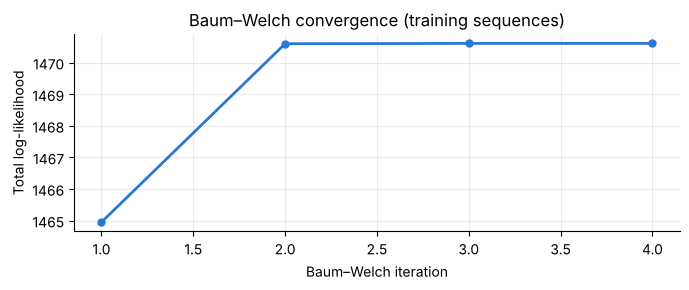

In [13]:
hmm_init = GaussianHMM(K).init_from_labels([(X, y) for X, y, _ in train_seqs])
hmm = hmm_init.copy()
hmm.baum_welch([X for X, _, _ in train_seqs])

# sanity check: EM must never decrease the likelihood (up to the tiny effect of the 1e-3 covariance regularizer)
assert np.all(np.diff(hmm.history) > -1e-2), 'log-likelihood decreased!'

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(1, len(hmm.history) + 1), hmm.history, 'o-', color='#2a78d6', ms=5, lw=2)
ax.set(xlabel='Baum–Welch iteration', ylabel='Total log-likelihood', title='Baum–Welch convergence (training sequences)')
plt.tight_layout(); savefig('06_baum_welch_convergence'); plt.show()

### Learned parameters: initial probabilities, transition matrix and emissions

Initial state probabilities π: {'Still': np.float64(0.333), 'Standing': np.float64(0.167), 'Walking': np.float64(0.417), 'Jumping': np.float64(0.083)}


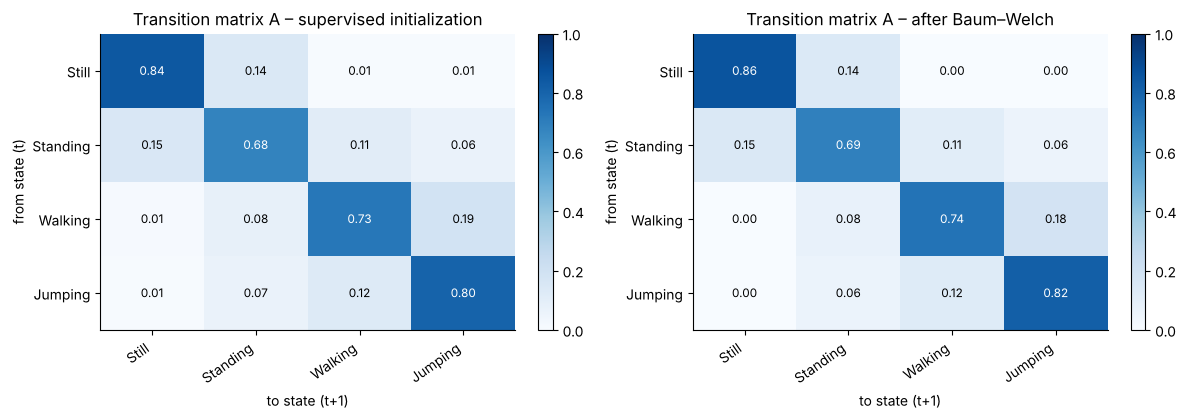

,Still,Standing,Walking,Jumping
Still,8.611e-01,0.139,1.669e-10,2.678e-47
Standing,1.462e-01,0.691,1.058e-01,5.689e-02
Walking,9.367e-10,0.075,7.413e-01,1.834e-01
Jumping,2.562e-48,0.061,1.212e-01,8.182e-01


In [14]:
def heat(ax, M, xt, yt, title, fmt='{:.2f}', cmap='Blues', vmin=None, vmax=None, cbar=True):
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')
    ax.set_xticks(range(len(xt))); ax.set_xticklabels(xt, rotation=35, ha='right')
    ax.set_yticks(range(len(yt))); ax.set_yticklabels(yt); ax.set_title(title); ax.grid(False)
    lim = np.nanmax(np.abs(M)) if vmax is None else vmax
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M[i, j]
            dark = (abs(v) > 0.6 * lim) if cmap != 'RdBu_r' else abs(v) > 0.55 * lim
            ax.text(j, i, fmt.format(v), ha='center', va='center', fontsize=8.5, color='white' if dark else 'black')
    if cbar: plt.colorbar(im, ax=ax, fraction=.046)

names = [LABELS[a] for a in ACTIVITIES]
print('Initial state probabilities π:', dict(zip(names, hmm.pi.round(3))))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
heat(ax[0], hmm_init.A, names, names, 'Transition matrix A – supervised initialization', vmin=0, vmax=1)
heat(ax[1], hmm.A, names, names, 'Transition matrix A – after Baum–Welch', vmin=0, vmax=1)
for a in ax: a.set_xlabel('to state (t+1)'); a.set_ylabel('from state (t)')
plt.tight_layout(); savefig('07_transition_matrix'); plt.show()
pd.DataFrame(hmm.A, index=names, columns=names)

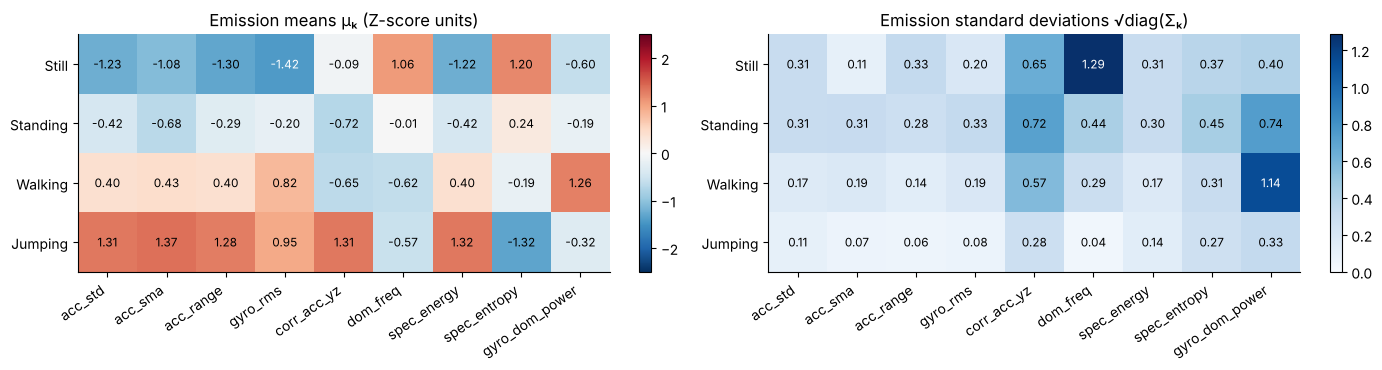

In [15]:
# Emission parameters: Gaussian means per state (in Z-score units) and their standard deviations
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
heat(ax[0], hmm.means, FEATURES, names, 'Emission means μₖ (Z-score units)', cmap='RdBu_r', vmin=-2.5, vmax=2.5)
heat(ax[1], np.sqrt(np.array([np.diag(c) for c in hmm.covs])), FEATURES, names,
     'Emission standard deviations √diag(Σₖ)', vmin=0)
plt.tight_layout(); savefig('08_emission_parameters'); plt.show()

A Gaussian emission is a density, not a table, so to show **emission probabilities** in table form we compute
for each true activity the average normalized emission probability
P(state k | x) ∝ N(x; μₖ, Σₖ) over its training windows. This shows which state’s emission distribution
“claims” each activity’s observations before any transition information is used.

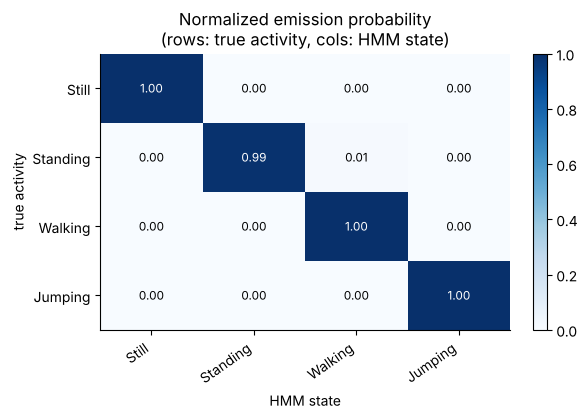

In [16]:
def emission_matrix(model, X, y):
    lb = model.log_emission(X)
    p = np.exp(lb - logsumexp(lb, axis=1, keepdims=True))
    return np.array([p[y == k].mean(0) for k in range(K)])

Xtr = np.vstack([X for X, _, _ in train_seqs]); ytr = np.concatenate([y for _, y, _ in train_seqs])
fig, ax = plt.subplots(figsize=(6, 4.3))
heat(ax, emission_matrix(hmm, Xtr, ytr), names, names, 'Normalized emission probability\n(rows: true activity, cols: HMM state)', vmin=0, vmax=1)
ax.set_xlabel('HMM state'); ax.set_ylabel('true activity')
plt.tight_layout(); savefig('09_emission_probabilities'); plt.show()

## 6. Evaluation on unseen data (session 5)
Each of the two unseen test sequences is decoded with Viterbi. Metrics are computed per window:
* **Sensitivity** (recall) = TP / (TP + FN): how many windows of this activity were found
* **Specificity** = TN / (TN + FP): how well the model avoids labelling other activities as this one
* **Accuracy** (per activity, one-vs-rest) = (TP + TN) / N; the overall accuracy = correct windows / all windows

In [17]:
def metrics_table(y_true, y_pred):
    cm = np.zeros((K, K), dtype=int)
    for t, p in zip(y_true, y_pred): cm[t, p] += 1
    N = cm.sum(); rows = []
    for k in range(K):
        TP = cm[k, k]; FN = cm[k].sum() - TP; FP = cm[:, k].sum() - TP; TN = N - TP - FN - FP
        rows.append({'State (Activity)': names[k], 'Number of Samples': int(cm[k].sum()),
                     'Sensitivity': TP / (TP + FN), 'Specificity': TN / (TN + FP),
                     'Accuracy (one-vs-rest)': (TP + TN) / N})
    return pd.DataFrame(rows), cm, np.trace(cm) / N

results = {}
for name, model in [('Supervised init only', hmm_init), ('After Baum–Welch', hmm)]:
    yt, yp = [], []
    for X, y, _ in test_seqs:
        path, _ = model.viterbi(X); yt.append(y); yp.append(path)
    results[name] = (np.concatenate(yt), np.concatenate(yp), yp)

# baseline without temporal model: classify each window independently by its emission likelihood
Xte = np.vstack([X for X, _, _ in test_seqs]); yte = np.concatenate([y for _, y, _ in test_seqs])
frame_pred = np.argmax(hmm.log_emission(Xte), axis=1)

print('Overall window accuracy on unseen test sequences')
for name, (yt, yp, _) in results.items():
    print(f'  {name:<25s}: {np.mean(yt == yp):.3f}')
print(f'  {"Emissions only (no HMM)":<25s}: {np.mean(frame_pred == yte):.3f}')
for i, (X, y, _) in enumerate(test_seqs, 1):
    print(f'  Test sequence {i} (Baum–Welch model): {np.mean(hmm.viterbi(X)[0] == y):.3f}   '
          f'log P(X|λ) = {hmm.score(X):.1f}')

y_true, y_pred, paths = results['After Baum–Welch']
table, cm, overall = metrics_table(y_true, y_pred)
print(f'\nFinal model (Baum–Welch), both unseen test sequences combined — overall accuracy = {overall:.3f}')
table.round(3)

Overall window accuracy on unseen test sequences
  Supervised init only     : 1.000
  After Baum–Welch         : 1.000
  Emissions only (no HMM)  : 1.000
  Test sequence 1 (Baum–Welch model): 1.000   log P(X|λ) = 158.9
  Test sequence 2 (Baum–Welch model): 1.000   log P(X|λ) = 164.9

Final model (Baum–Welch), both unseen test sequences combined — overall accuracy = 1.000


,State (Activity),Number of Samples,Sensitivity,Specificity,Accuracy (one-vs-rest)
0,Still,39,1.0,1.0,1.0
1,Standing,29,1.0,1.0,1.0
2,Walking,35,1.0,1.0,1.0
3,Jumping,34,1.0,1.0,1.0


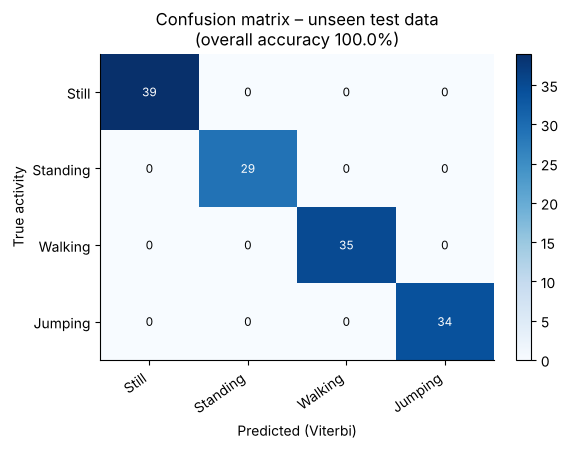

In [18]:
fig, ax = plt.subplots(figsize=(5.8, 4.6))
heat(ax, cm, names, names, f'Confusion matrix – unseen test data\n(overall accuracy {overall:.1%})', fmt='{:d}')
ax.set_xlabel('Predicted (Viterbi)'); ax.set_ylabel('True activity')
plt.tight_layout(); savefig('10_confusion_matrix'); plt.show()

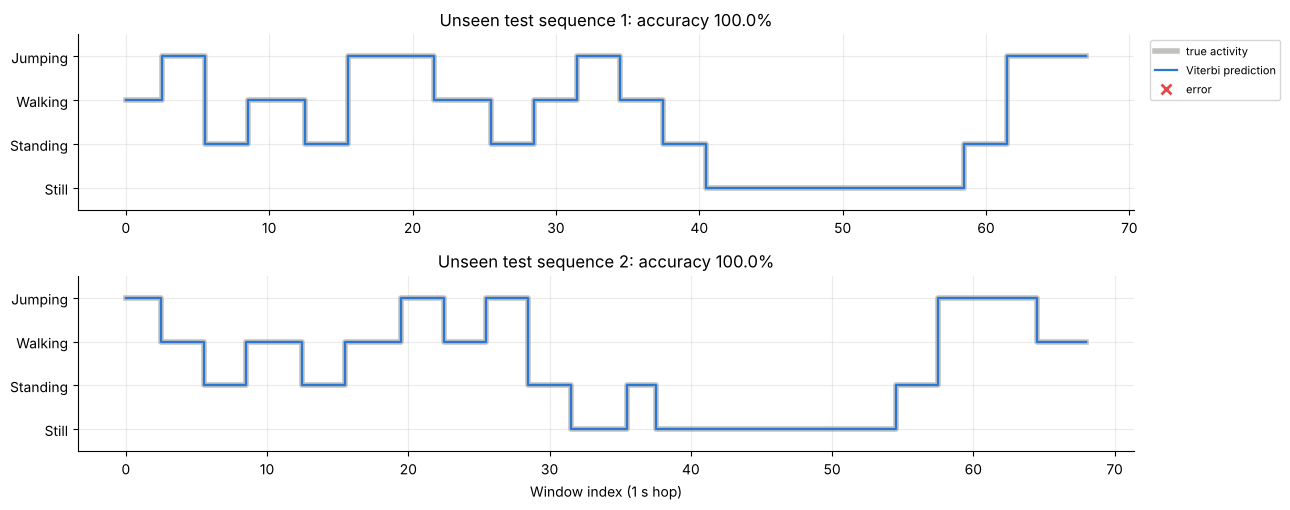

In [19]:
# Decoded sequences vs ground truth
fig, axes = plt.subplots(2, 1, figsize=(13, 5.2))
for ax, (X, y, df), path, i in zip(axes, test_seqs, paths, (1, 2)):
    t = np.arange(len(y))
    ax.step(t, y, where='mid', color='#9a9994', lw=4, alpha=.6, label='true activity')
    ax.step(t, path, where='mid', color='#2a78d6', lw=1.6, label='Viterbi prediction')
    wrong = path != y
    ax.plot(t[wrong], path[wrong], 'x', color='#e34948', ms=7, mew=2, label='error')
    ax.set_yticks(range(K)); ax.set_yticklabels(names); ax.set_ylim(-.5, K - .5)
    ax.set_title(f'Unseen test sequence {i}: accuracy {np.mean(~wrong):.1%}')
axes[0].legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8); axes[1].set_xlabel('Window index (1 s hop)')
plt.tight_layout(); savefig('11_decoded_sequences'); plt.show()

In [20]:
# Per-recording result: majority vote of the Viterbi labels inside each unseen recording
rec_rows = []
for (X, y, df), path in zip(test_seqs, paths):
    d = df[['recording', 'activity']].copy(); d['pred'] = [ACTIVITIES[p] for p in path]
    for rec, g in d.groupby('recording', sort=False):
        rec_rows.append({'recording': rec, 'true': LABELS[g.activity.iloc[0]],
                         'predicted (majority)': LABELS[g.pred.mode()[0]],
                         'windows correct': f'{(g.pred == g.activity).sum()}/{len(g)}'})
per_rec = pd.DataFrame(rec_rows)
print(f"Recordings classified correctly by majority vote: "
      f"{(per_rec['true'] == per_rec['predicted (majority)']).sum()}/{len(per_rec)}")
per_rec[per_rec['true'] != per_rec['predicted (majority)']]

Recordings classified correctly by majority vote: 40/40


,recording,true,predicted (majority),windows correct


### Robustness check 1: leave-one-session-out cross-validation
Session 5 is a single held-out session, and a perfect or near-perfect score on one session could be luck.
We therefore repeat the **whole training pipeline 5 times**, holding out each session in turn.
Each repetition refits the Z-score statistics, the supervised initialization and Baum–Welch on the other 4 sessions
and decodes the held-out session’s 2 routine sequences with Viterbi.

In [21]:
def run_fold(test_session, seed=0):
    rng_f = np.random.default_rng(seed)
    tr = windows.session != test_session
    Zf = windows.copy()
    Zf[FEATURES] = (windows[FEATURES] - windows.loc[tr, FEATURES].mean()) / windows.loc[tr, FEATURES].std()
    tr_seqs = make_sequences([s for s in range(1, 6) if s != test_session], Zf, rng_f)
    te_seqs = make_sequences([test_session], Zf, rng_f)
    m = GaussianHMM(K).init_from_labels([(X, y) for X, y, _, _ in tr_seqs])
    m.baum_welch([X for X, _, _, _ in tr_seqs], verbose=False)
    yt = np.concatenate([y for _, y, _, _ in te_seqs])
    yp = np.concatenate([m.viterbi(X)[0] for X, _, _, _ in te_seqs])
    ye = np.concatenate([np.argmax(m.log_emission(X), 1) for X, _, _, _ in te_seqs])
    tab, cm_f, acc = metrics_table(yt, yp)
    return {'held-out session': test_session, 'test windows': len(yt), 'BW iterations': m.n_iter_,
            'HMM accuracy': acc, 'emissions-only accuracy': np.mean(ye == yt),
            **{f'sens {n}': v for n, v in zip(names, tab.Sensitivity)}}, cm_f

cv_rows, cv_cm = [], np.zeros((K, K), dtype=int)
for s in range(1, 6):
    row, cm_f = run_fold(s); cv_rows.append(row); cv_cm += cm_f
cv = pd.DataFrame(cv_rows)
print(f"Leave-one-session-out: mean HMM accuracy {cv['HMM accuracy'].mean():.3f} "
      f"(min {cv['HMM accuracy'].min():.3f}); emissions-only {cv['emissions-only accuracy'].mean():.3f}")
cv_table, _, cv_overall = metrics_table(*[np.repeat(np.arange(K), cv_cm.sum(1)),
                                          np.concatenate([np.repeat(np.arange(K), cv_cm[k]) for k in range(K)])])
cv.round(3)

Leave-one-session-out: mean HMM accuracy 0.995 (min 0.991); emissions-only 0.989


,held-out session,test windows,BW iterations,HMM accuracy,emissions-only accuracy,sens Still,sens Standing,sens Walking,sens Jumping
0,1,150,16,0.993,0.960,1.0,0.977,1.0,1.000
1,2,116,4,0.991,0.991,1.0,0.958,1.0,1.000
2,3,137,6,0.993,0.993,1.0,1.000,1.0,0.973
3,4,124,6,1.000,1.000,1.0,1.000,1.0,1.000
4,5,137,4,1.000,1.000,1.0,1.000,1.0,1.000


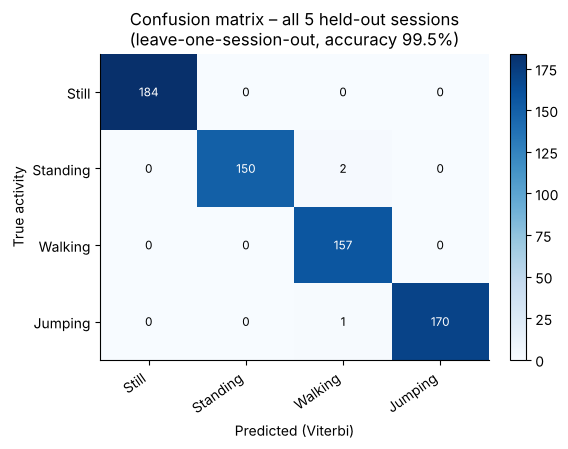

,State (Activity),Number of Samples,Sensitivity,Specificity,Accuracy (one-vs-rest)
0,Still,184,1.000,1.000,1.000
1,Standing,152,0.987,1.000,0.997
2,Walking,157,1.000,0.994,0.995
3,Jumping,171,0.994,1.000,0.998


In [22]:
fig, ax = plt.subplots(figsize=(5.8, 4.6))
heat(ax, cv_cm, names, names, f'Confusion matrix – all 5 held-out sessions\n(leave-one-session-out, accuracy {cv_overall:.1%})', fmt='{:d}')
ax.set_xlabel('Predicted (Viterbi)'); ax.set_ylabel('True activity')
plt.tight_layout(); savefig('12_confusion_matrix_cv'); plt.show()
cv_table.round(3)

### Robustness check 2: Baum–Welch from an uninformed start
The main model starts Baum–Welch from labelled estimates. To check that our Baum–Welch implementation can
*discover* the activities by itself, we also train it **without using any labels**. The means are k-means++
picks of random training windows, the covariances are the global covariance, π is uniform and A has 0.7 on the
diagonal. We run 5 random restarts and keep the one with the highest log-likelihood. Only afterwards are the
learned states matched to activity names (Hungarian assignment on the training windows), and the model is
then evaluated on the unseen test sequences.

restart 0:   9 iterations, final log-likelihood   1283.95
restart 1:  21 iterations, final log-likelihood    787.33
restart 2:  35 iterations, final log-likelihood   1445.45
restart 3:  18 iterations, final log-likelihood   1483.46
restart 4:  34 iterations, final log-likelihood   1509.76

Unsupervised Baum–Welch (best restart, 34 iterations): accuracy on unseen test sequences = 0.964
Its training log-likelihood (1509.8) is HIGHER than the label-initialized model (1470.6), yet its accuracy is lower: maximum likelihood does not guarantee states that match human labels.

Confusion matrix of the unsupervised model on the test sequences (rows true, cols predicted):
          Still  Standing  Walking  Jumping
Still        39         0        0        0
Standing      0        24        5        0
Walking       0         0       35        0
Jumping       0         0        0       34


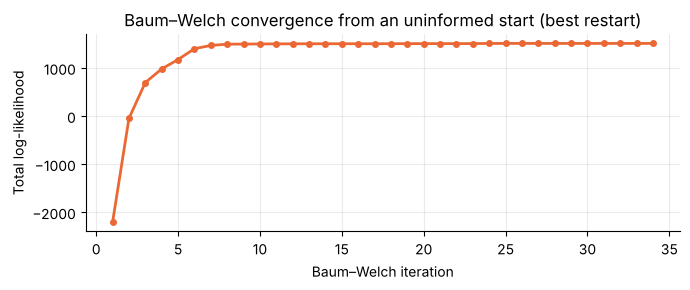

In [23]:
from scipy.optimize import linear_sum_assignment

def random_init(X, k, rng):
    m = GaussianHMM(k)
    centers = [X[rng.integers(len(X))]]
    for _ in range(k - 1):                                            # k-means++ seeding
        d2 = np.min([((X - c) ** 2).sum(1) for c in centers], axis=0)
        centers.append(X[rng.choice(len(X), p=d2 / d2.sum())])
    m.means = np.array(centers)
    m.covs = np.array([np.cov(X.T) + m.reg * np.eye(X.shape[1])] * k)
    m.pi = np.full(k, 1 / k); m.A = np.full((k, k), 0.3 / (k - 1)); np.fill_diagonal(m.A, 0.7)
    return m

rng_u = np.random.default_rng(3)
best = None
for restart in range(5):
    m = random_init(Xtr, K, rng_u).baum_welch([X for X, _, _ in train_seqs], verbose=False)
    print(f'restart {restart}: {m.n_iter_:3d} iterations, final log-likelihood {m.history[-1]:9.2f}')
    if best is None or m.history[-1] > best.history[-1]: best = m

# map learned states -> activity names using the training labels (only for naming the states)
states_tr = np.concatenate([best.viterbi(X)[0] for X, _, _ in train_seqs])
overlap = np.array([[np.sum((states_tr == s) & (ytr == a)) for a in range(K)] for s in range(K)])
_, mapping = linear_sum_assignment(-overlap)
yp_u = np.concatenate([mapping[best.viterbi(X)[0]] for X, _, _ in test_seqs])
print(f'\nUnsupervised Baum–Welch (best restart, {best.n_iter_} iterations): '
      f'accuracy on unseen test sequences = {np.mean(yp_u == yte):.3f}')
print(f'Its training log-likelihood ({best.history[-1]:.1f}) is HIGHER than the label-initialized model '
      f'({hmm.history[-1]:.1f}), yet its accuracy is lower: maximum likelihood does not guarantee states that match human labels.')
print('\nConfusion matrix of the unsupervised model on the test sequences (rows true, cols predicted):')
print(pd.DataFrame(metrics_table(yte, yp_u)[1], index=names, columns=names).to_string())

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(1, len(best.history) + 1), best.history, 'o-', color='#eb6834', ms=4, lw=2)
ax.set(xlabel='Baum–Welch iteration', ylabel='Total log-likelihood',
       title='Baum–Welch convergence from an uninformed start (best restart)')
plt.tight_layout(); savefig('13_baum_welch_unsupervised'); plt.show()

In [24]:
# Save results for the report
table.round(3).to_csv(f'{FIG_DIR}/metrics_table.csv', index=False)
cv_table.round(3).to_csv(f'{FIG_DIR}/metrics_table_cv.csv', index=False)
cv.round(4).to_csv(f'{FIG_DIR}/cv_per_session.csv', index=False)
pd.DataFrame(cm, index=names, columns=names).to_csv(f'{FIG_DIR}/confusion_matrix.csv')
pd.DataFrame(hmm.A, index=names, columns=names).round(4).to_csv(f'{FIG_DIR}/transition_matrix.csv')
json.dump({'overall_accuracy': overall, 'n_iter': hmm.n_iter_, 'loglik_history': hmm.history,
           'pi': dict(zip(names, hmm.pi.round(4).tolist())),
           'acc_supervised_only': float(np.mean(results['Supervised init only'][0] == results['Supervised init only'][1])),
           'acc_emissions_only': float(np.mean(frame_pred == yte)),
           'cv_accuracy_per_session': cv['HMM accuracy'].round(4).tolist(), 'cv_overall': cv_overall,
           'cv_emissions_only_mean': float(cv['emissions-only accuracy'].mean()),
           'unsupervised_bw_accuracy': float(np.mean(yp_u == yte)), 'unsupervised_bw_iters': best.n_iter_},
          open(f'{FIG_DIR}/summary.json', 'w'), indent=2)
print('Saved figures and tables to', FIG_DIR)

Saved figures and tables to figures
